In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pop = pd.read_csv("API_SP.POP.TOTL_DS2_en_csv_v2_38144.csv", skiprows=4)
meta = pd.read_csv("Metadata_Country_API_SP.POP.TOTL_DS2_en_csv_v2_38144.csv")

print(pop.head())
print(pop.columns)

                  Country Name Country Code     Indicator Name Indicator Code  \
0                        Aruba          ABW  Population, total    SP.POP.TOTL   
1  Africa Eastern and Southern          AFE  Population, total    SP.POP.TOTL   
2                  Afghanistan          AFG  Population, total    SP.POP.TOTL   
3   Africa Western and Central          AFW  Population, total    SP.POP.TOTL   
4                       Angola          AGO  Population, total    SP.POP.TOTL   

          1960         1961         1962         1963         1964  \
0      54922.0      55578.0      56320.0      57002.0      57619.0   
1  130075728.0  133534923.0  137171659.0  140945536.0  144904094.0   
2    9035043.0    9214083.0    9404406.0    9604487.0    9814318.0   
3   97630925.0   99706674.0  101854756.0  104089175.0  106388440.0   
4    5231654.0    5301583.0    5354310.0    5408320.0    5464187.0   

          1965  ...         2016         2017         2018         2019  \
0      58190.0  .

In [7]:
df = pop.merge(meta[["Country Code", "Region", "IncomeGroup"]], on="Country Code")
df = df.dropna(subset=["Region"])   # removes aggregates like "World", "Africa Eastern and Southern"
print(df.shape)

(217, 72)


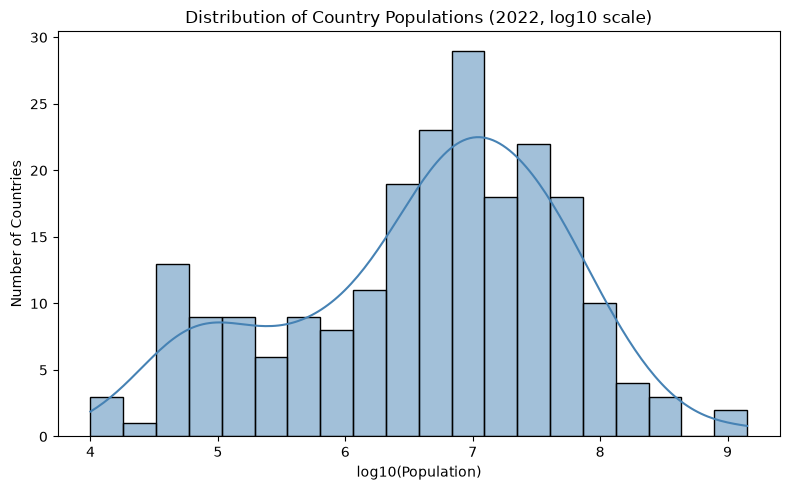

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(np.log10(df["2022"].dropna()), bins=20, kde=True, color="steelblue")
plt.title("Distribution of Country Populations (2022, log10 scale)")
plt.xlabel("log10(Population)")
plt.ylabel("Number of Countries")
plt.tight_layout()
plt.savefig("histogram_population.png", dpi=150)
plt.show()

**Insight:** Most countries have populations of around 1 million to 100 million,
with the peak near 10 million. A smaller group of very small nations sits near
100,000 people, while only two countries (India and China) cross 1 billion.
The data is highly skewed, so a log scale was used to show the full distribution.

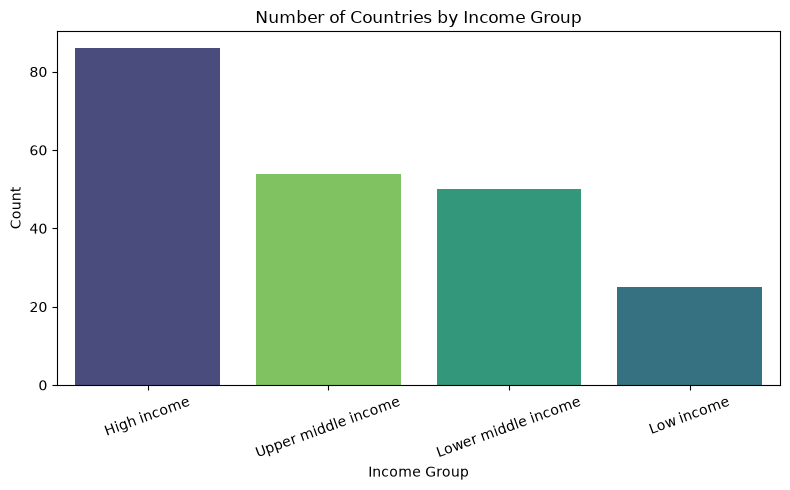

In [9]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="IncomeGroup",
              order=df["IncomeGroup"].value_counts().index,
              hue="IncomeGroup", palette="viridis", legend=False)
plt.title("Number of Countries by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("barchart_income_group.png", dpi=150)
plt.show()

**Insight:** High income is the largest group with 86 countries, followed by
Upper middle income (54) and Lower middle income (50). Low income is the
smallest group with only 25 countries. Together, the two middle-income groups
(104 countries) make up almost half of all countries in the dataset.